# Session 1 复现：理解与改进机器学习模型（结果、调参与误差分析）

本文对应课程 *Understanding and Improving Machine Learning Models: Results, Tuning and Error Analysis*
（`00-worked-example.html`）。目标是**逐节复现**课程中的每一个数字与每一张图，并把
课程正文里"只给了结论、没给代码"的部分补上。

**场景**：Dr Epona 想用"半眨眼 / 全眨眼"的比例作为马匹压力指标。人工逐帧标注太慢，
于是把一次眨眼拆成三段时长，用机器学习来做分类。

| | 定义 |
|---|---|
| 输入 | `closing_duration`、`paused_duration`、`opening_duration` 三个时长特征 |
| 输出 | 眨眼类型：`F`（full，全眨眼）或 `H`（half，半眨眼） |
| 数据 | 186 个眨眼事件，来自 19 段视频、4 匹马 |
| 评价 | 分层 5 折交叉验证 |

本 notebook 的所有绘图都同时保存到 `figures/`，所有表格保存到 `outputs/`。

In [1]:
import sys
from pathlib import Path

PROJECT = Path.cwd()
if (PROJECT / "src").exists():
    sys.path.insert(0, str(PROJECT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import config

config.setup_matplotlib()

import eda
import models
import errors

pd.set_option("display.width", 120)
print("项目目录:", PROJECT)

项目目录: E:\_Materials_in_NWPU_\2026_Spring\project\Aberystwyth University\日程\AI sessions\project


## 1. 数据长什么样

课程跳过了"从原始标注文件生成特征"的步骤（导入标注 → 用视频元数据把帧号换成秒 →
检查缺失 → 计算三段时长），直接从清洗好的 `blink_events.csv` 开始。我们也从这里开始。

原始表只有 8 列；复现时补一列 `total_duration`（三段时长之和），因为课程正文讨论
过"只用总时长分不开两类"这件事，却把对应的代码省略了。

In [2]:
blink_events = eda.load_blink_events()
print(blink_events.columns.tolist())
blink_events.iloc[0:5]

['Blink_event', 'Blink_type', 'video_id', 'Horse_ID', 'duration', 'closing_duration', 'paused_duration', 'opening_duration', 'blink_id', 'total_duration']


,Blink_event,Blink_type,video_id,Horse_ID,duration,closing_duration,paused_duration,opening_duration,blink_id,total_duration
0,1,H,G-004,G,0.183333,0.050000,0.033333,0.100000,0,0.183333
1,2,F,G-004,G,0.466667,0.100000,0.033333,0.333333,1,0.466667
2,3,H,G-004,G,0.316667,0.083333,0.016667,0.216667,2,0.316667
3,4,H,G-004,G,0.266667,0.083333,0.016667,0.166667,3,0.266667
4,5,F,G-005,G,0.400000,0.133333,0.033333,0.233333,4,0.400000


In [3]:
info = eda.describe_dataset(blink_events)
print(f"事件数: {info['n_events']} | 视频数: {info['n_videos']} | 马匹数: {info['n_horses']}")
print(f"类别计数: {info['counts']} | 缺失值: {info['missing_values']}")

事件数: 186 | 视频数: 19 | 马匹数: 4
类别计数: {'F': 105, 'H': 81} | 缺失值: 0


### 位置索引（`iloc`）

课程用一道小题提醒：Python 的切片**含头不含尾**。`iloc[5:10]` 给的是第 6–10 个事件
（索引 5,6,7,8,9）。

In [4]:
blink_events.iloc[5:10]

,Blink_event,Blink_type,video_id,Horse_ID,duration,closing_duration,paused_duration,opening_duration,blink_id,total_duration
5,6,H,G-005,G,0.350000,0.116667,0.016667,0.216667,5,0.350000
6,7,H,G-005,G,0.216667,0.083333,0.016667,0.116667,6,0.216667
7,8,H,G-005,G,0.266667,0.083333,0.016667,0.166667,7,0.266667
8,9,F,M-002,M,0.792327,0.208507,0.041701,0.542118,8,0.792327
9,10,F,M-002,M,0.625521,0.208507,0.041701,0.375313,9,0.625521


## 2. 特征有用吗？

先看课程给出的两个关键观察：

1. **只用总时长分不开两类** —— 分布大量重叠；
2. **三段时长比总时长更有信息** —— 但仍有重叠，所以需要用三者的组合。

复现时我在直方图之外补了一个**与阈值无关**的量化指标：单特征 ROC-AUC。
原因是"直方图看起来分得开不开"很受分箱方式与样本量影响，而 AUC 只看排序。

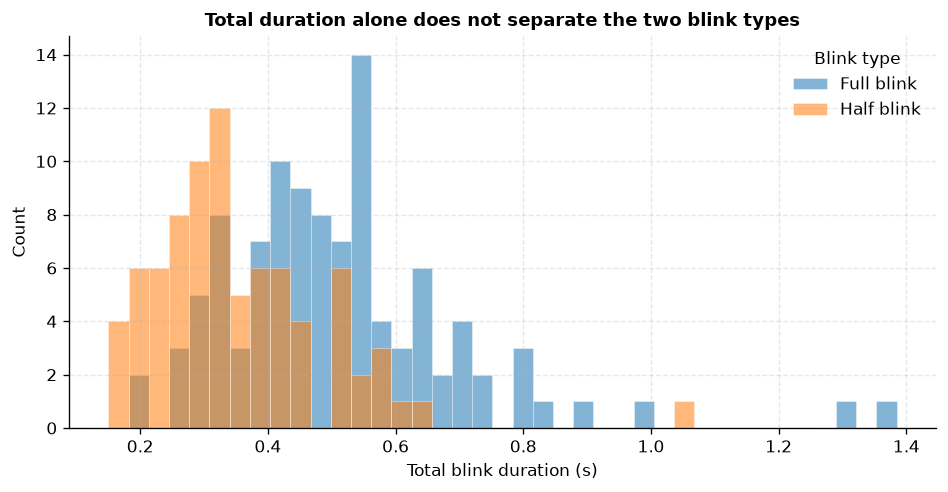

In [5]:
eda.plot_total_duration(blink_events);

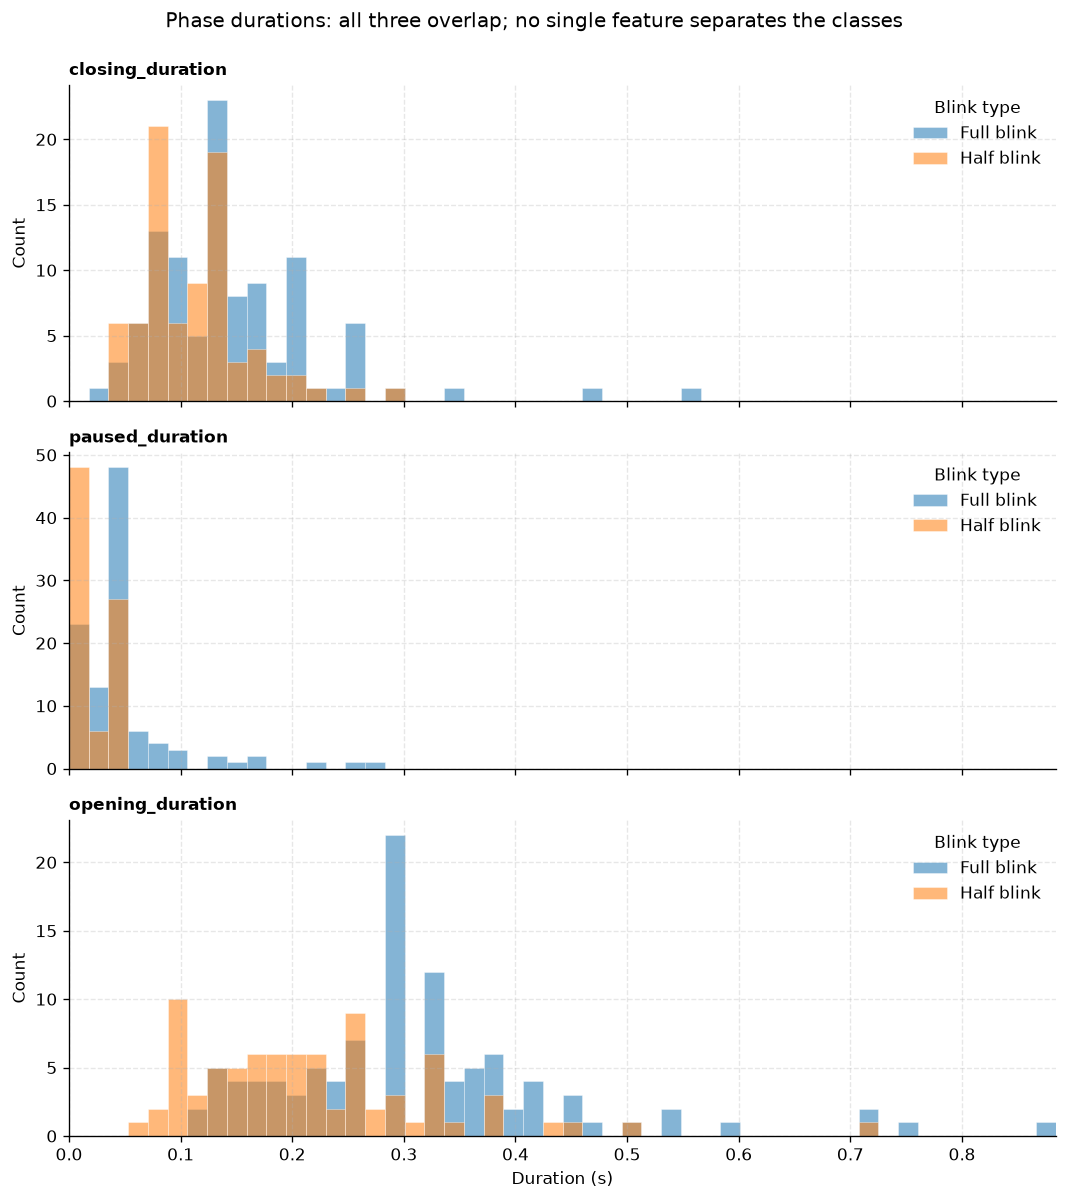

In [6]:
eda.plot_feature_distributions(blink_events);

In [7]:
eda.feature_separability_table(blink_events)

,feature,univariate_auc,overlap_coefficient,median_F,median_H
1,paused_duration,0.793,0.626,0.0417,0.0167
3,total_duration,0.783,0.485,0.4838,0.3333
2,opening_duration,0.738,0.543,0.2919,0.2002
0,closing_duration,0.661,0.717,0.1335,0.1167


**复现发现（与课程叙述略有出入，值得记录）**

课程正文说 `opening_duration` 的分离最明显。但从 AUC 看：

* `paused_duration` 0.79 > `total_duration` 0.78 > `opening_duration` 0.74 > `closing_duration` 0.66

`opening_duration` 的直方图之所以"看起来"分离得好，是因为全眨眼的分布右移且更宽，
视觉上更容易分辨；但若把特征当分数直接判别，`paused_duration` 反而更有效。

另一个细节：`paused_duration` 被 60 fps 的帧率量化（0.0167 s 的整数倍），分布是离散尖峰。
因此基于密度的"重叠系数"在这一列上并不可靠，而基于秩的 AUC 不受影响。
这也是一个教学点：**指标的假设要匹配数据的性质**。

## 3. 类别不平衡与"懒惰模型"

全眨眼 105 个、半眨眼 81 个。若不看类别直接报准确率，一个永远预测"全眨眼"的模型
也能拿到 56%。这个数字就是后续所有准确率的**下限参考**。

Blink_type
F    105
H     81
Name: count, dtype: int64

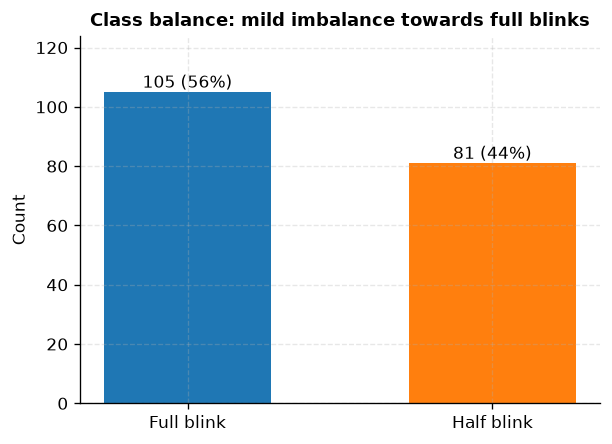

In [8]:
fig, class_counts = eda.plot_class_balance(blink_events)
class_counts

In [9]:
X, y = models.get_X_y(blink_events)
skf = models.make_skf()
lazy_accuracy = models.lazy_baseline(X, y, skf)
print(f"Lazy baseline accuracy: {lazy_accuracy:.2f}")
print(f"直接算多数类占比: {(y == 'F').mean():.2f}")

Lazy baseline accuracy: 0.56
直接算多数类占比: 0.56


## 4. 交叉验证设置

样本只有 186 个，单次 train/test 划分很容易抽到"特别简单"或"特别难"的一组事件。
课程改用**分层 5 折交叉验证**（每折里全/半眨眼比例与整体一致），并用
`random_state` 固定划分，使结果可复现。

In [10]:
for seed in [1, 2, 3]:
    folds = models.make_skf(random_state=seed)
    sizes = [len(test) for _, test in folds.split(X, y)]
    print(f"random_state={seed}: 每折验证集大小 {sizes}")

random_state=1: 每折验证集大小 [38, 37, 37, 37, 37]
random_state=2: 每折验证集大小 [38, 37, 37, 37, 37]
random_state=3: 每折验证集大小 [38, 37, 37, 37, 37]


## 5. 第一个模型：决策树

决策树用一连串"是/否"问题把样本分到叶子。课程先设 `max_depth=10`，得到 0.76；
再扫描 1–10 的深度，发现**更复杂不等于更准**。

In [11]:
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_predict
from sklearn.tree import DecisionTreeClassifier

tree_deep = DecisionTreeClassifier(random_state=1, max_depth=10)
tree_deep_pred = cross_val_predict(tree_deep, X, y, cv=skf)
print(f"Decision tree (depth 10) accuracy: {accuracy_score(y, tree_deep_pred):.2f}")

Decision tree (depth 10) accuracy: 0.76


,max_depth,accuracy
0,1,0.7527
1,2,0.7527
2,3,0.7634
3,4,0.7796
4,5,0.7688
5,6,0.7796
6,7,0.7581
7,8,0.7581
8,9,0.7473
9,10,0.7581


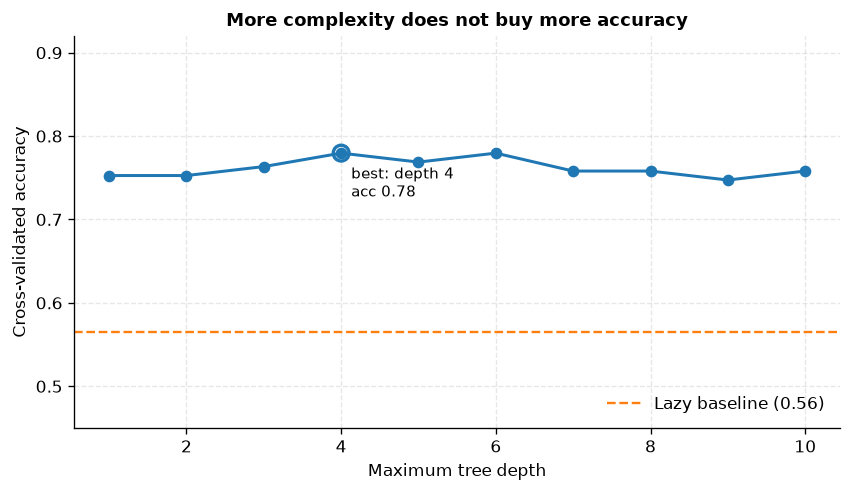

In [12]:
depth_table = models.depth_sweep(X, y, skf)
models.plot_depth_sweep(depth_table, lazy_accuracy)
depth_table.round(4)

准确率在 0.75–0.78 之间来回波动，没有随深度单调上升。课程据此选 `max_depth=4`
作为"准确率与简洁性之间的折中"。

In [13]:
tree_4 = DecisionTreeClassifier(random_state=1, max_depth=4)
tree_pred = cross_val_predict(tree_4, X, y, cv=skf)
print(f"Decision tree (depth 4) accuracy: {accuracy_score(y, tree_pred):.2f}")

Decision tree (depth 4) accuracy: 0.78


In [14]:
complexity, tree_models = models.tree_complexity_table(X, y, depths=(1, 4, 10))
complexity

,max_depth,actual_depth,n_leaves
0,1,1,2
1,4,4,11
2,10,10,41


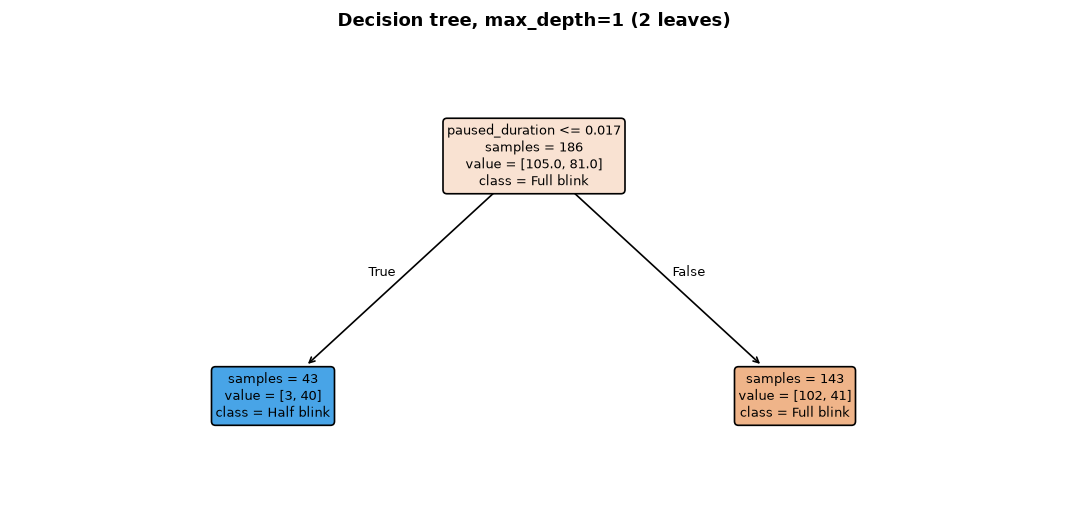

In [15]:
models.plot_tree_structure(tree_models[1], X, "fig07_tree_depth1", figsize=(9, 4.5));

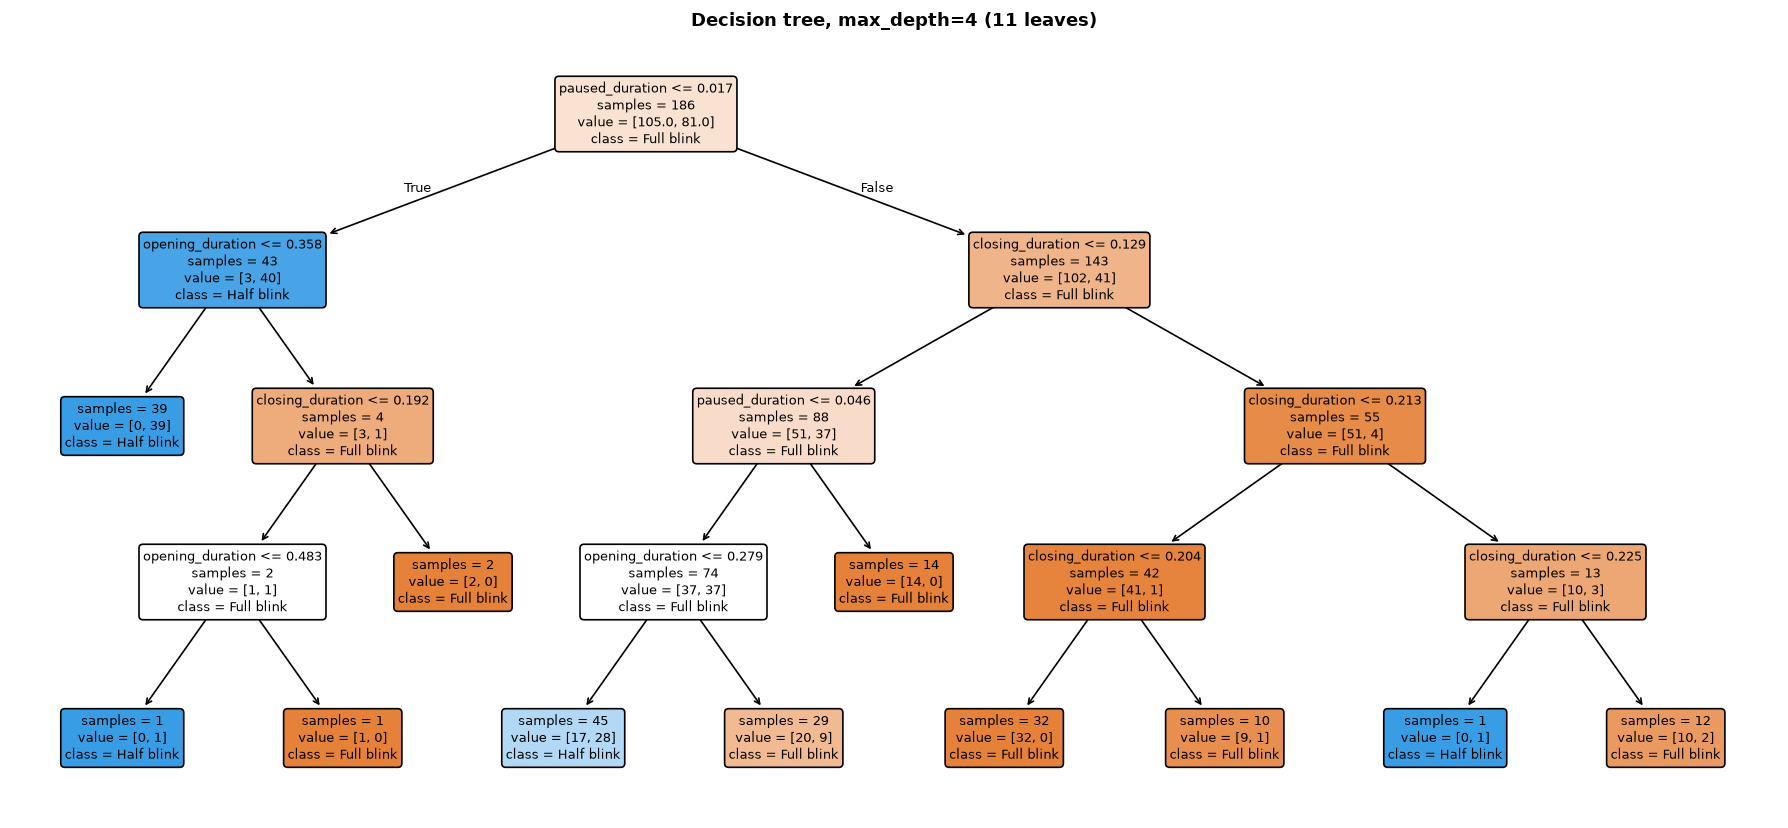

In [16]:
models.plot_tree_structure(tree_models[4], X, "fig08_tree_depth4", figsize=(15, 7));

depth=10 的树已经有 41 个叶子，画出来几乎无法阅读。课程用**最窄的阈值区间**来
说明过拟合：某个内部节点的切分条件是
`0.01667223 < paused_duration <= 0.01668474`，区间宽度只有 $10^{-5}$ 秒，
而 60 fps 下一帧是 0.0167 秒 —— 这个切分把**一个样本**单独切了出来。

下面用代码把"最窄切分"自动找出来。由于绘图用的树以 `random_state=0` 拟合（课程的
可视化代码也是），具体节点与课程截图略有不同，但结论一致：最窄区间在
$10^{-5}$ 秒量级，即**一帧的千分之一**，物理上不可能是真实的行为差异。

In [17]:
narrow = models.narrowest_split(tree_models[10])
print(f"最窄切分所在的特征: {X.columns[narrow['feature_index']]}")
print(f"区间: ({narrow['lower']:.8f}, {narrow['upper']:.8f}]")
print(f"宽度: {narrow['width']:.2e} 秒")
print(f"一帧 = {narrow['frame_seconds']:.6f} 秒")
print(f"宽度/一帧 = {narrow['width'] / narrow['frame_seconds']:.4f}")

最窄切分所在的特征: paused_duration
区间: (0.03336114, 0.03336948]
宽度: 8.35e-06 秒
一帧 = 0.016686 秒
宽度/一帧 = 0.0005


## 6. 第二个模型：随机森林

随机森林把很多棵树的结果投票，比单棵树稳定，代价是更难解释。
课程先给 100 棵、深度 10 → 0.77；再穷举 60 种超参组合，最好的组合是
`n_estimators=75, max_depth=6, min_samples_leaf=1` → 0.81。

In [18]:
forest_default_pred = cross_val_predict(models.default_forest(), X, y, cv=skf)
print(f"Random forest (100 trees, depth 10) accuracy: "
      f"{accuracy_score(y, forest_default_pred):.2f}")

Random forest (100 trees, depth 10) accuracy: 0.77


,n_estimators,max_depth,min_samples_leaf,accuracy
28,75,6,1,0.811828
8,50,6,1,0.806452
12,50,8,1,0.806452
4,50,4,1,0.806452
29,75,6,3,0.806452
45,150,4,3,0.806452
24,75,4,1,0.801075
48,150,6,1,0.801075
33,75,8,3,0.801075
7,50,4,7,0.801075


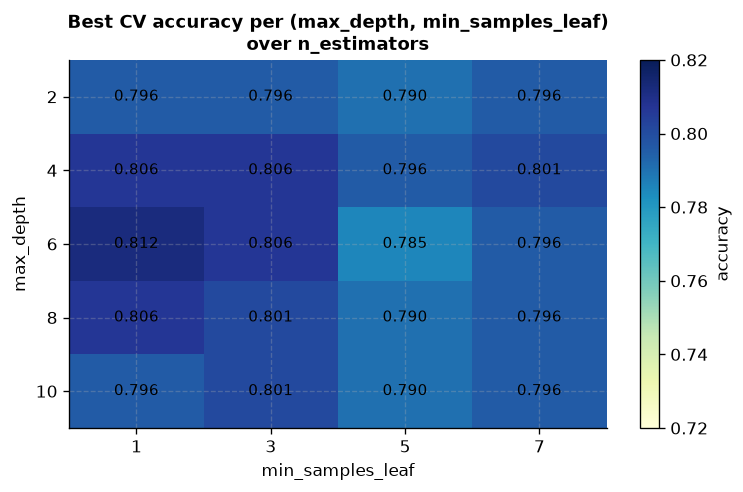

In [19]:
grid = models.forest_grid(X, y, skf)
models.plot_forest_grid(grid)
grid.head(10)

In [20]:
forest_pred = cross_val_predict(models.tuned_forest(), X, y, cv=skf)
print(f"Random forest (75 trees, depth 6) accuracy: {accuracy_score(y, forest_pred):.2f}")

Random forest (75 trees, depth 6) accuracy: 0.81


## 7. 混淆矩阵与分类型召回率

准确率是一个数字，混淆矩阵告诉你**错在哪一类**。

复现结果与课程完全一致：

| 模型 | 全眨眼召回 | 半眨眼召回 | 准确率 |
|---|---|---|---|
| 决策树 | 76% | 80% | 0.78 |
| 随机森林 | 86% | 74% | 0.81 |

随机森林的总准确率更高，但它是**牺牲半眨眼召回**换来的 —— 而这恰好是 Dr Epona
最关心的那一类。

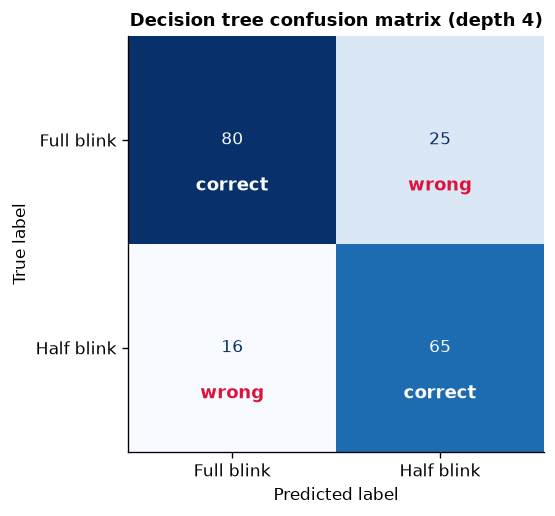

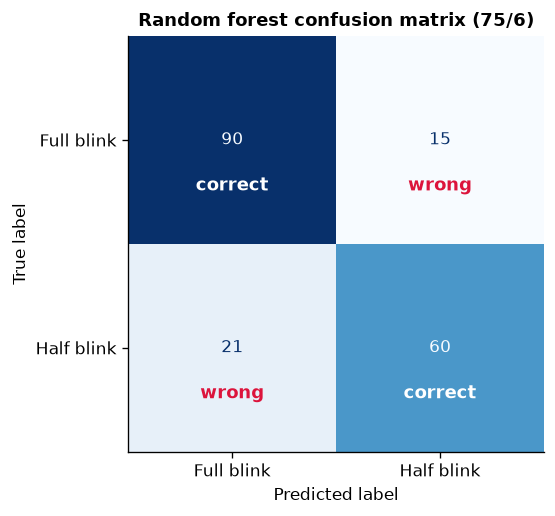

In [21]:
models.plot_confusion(y, tree_pred, "Decision tree confusion matrix (depth 4)",
                      "fig09_cm_tree");
models.plot_confusion(y, forest_pred, "Random forest confusion matrix (75/6)",
                      "fig10_cm_forest");

In [22]:
models.recall_table(y, {"Decision tree": tree_pred, "Random forest": forest_pred})

,Model,Full blink recall,Half blink recall,Accuracy
0,Decision tree,76%,80%,78%
1,Random forest,86%,74%,81%


## 8. 重复评估：分数稳不稳？

一次 5 折 CV 只给出一个估计。用 10 组不同的随机划分重复，就能看出这个估计对
"怎么分折"有多敏感。

Mean random forest accuracy: 0.80
Standard deviation: 0.01


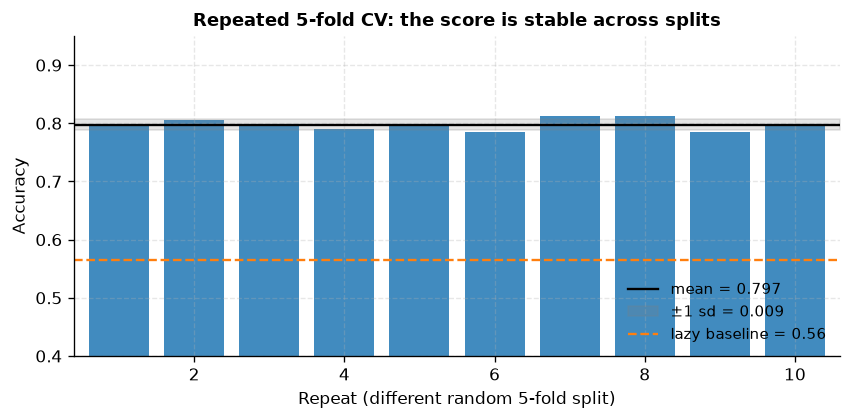

In [23]:
scores, repeated_predictions = models.repeated_cv(X, y, models.tuned_forest, blink_events)
print(f"Mean random forest accuracy: {scores.mean():.2f}")
print(f"Standard deviation: {scores.std():.2f}")
models.plot_repeated_scores(scores, lazy_accuracy);

均值 0.80、标准差 0.01 —— 分数很稳，说明它不依赖某一组幸运的折。
但"稳"不等于"对"：它只说明**在这套特征、这个数据集上**结果可重复。
这一点在第 09 个 notebook 的延伸分析里会用分组交叉验证和置换检验继续追问。

## 9. 误差分析：哪些样本被反复判错？

10 次重复 × 5 折 = 每个事件有 10 个"没在训练时见过"的预测。
数一下每个事件被判错了几次，就能区分"偶发错误"和"系统性困难样本"。

In [24]:
summary, consistently = errors.event_error_summary(repeated_predictions, threshold=5)
print(f"至少错过一次的事件数: {len(summary)} / {len(blink_events)}")
print(f"反复判错（>5 次）的事件数: {len(consistently)}")
summary.head(12)

至少错过一次的事件数: 60 / 186
反复判错（>5 次）的事件数: 36


,blink_id,times_incorrect
13,13,10
11,11,10
19,19,10
16,16,10
51,51,10
49,49,10
21,21,10
84,84,10
79,79,10
64,64,10


In [25]:
blink_with_errors = errors.attach_errors(blink_events, summary)
mispredicted = blink_with_errors[blink_with_errors["times_incorrect"] > 5]
mispredicted[["blink_id", "Blink_type", "times_incorrect", "video_id", "Horse_ID"]].head(20)

,blink_id,Blink_type,times_incorrect,video_id,Horse_ID
0,0,H,6,G-004,G
11,11,H,10,M-002,M
13,13,H,10,M-002,M
16,16,H,10,M-002,M
19,19,H,10,M-003,M
21,21,H,10,M-003,M
49,49,H,10,M-006,M
50,50,H,7,M-006,M
51,51,H,10,M-006,M
60,60,H,10,M-006,M


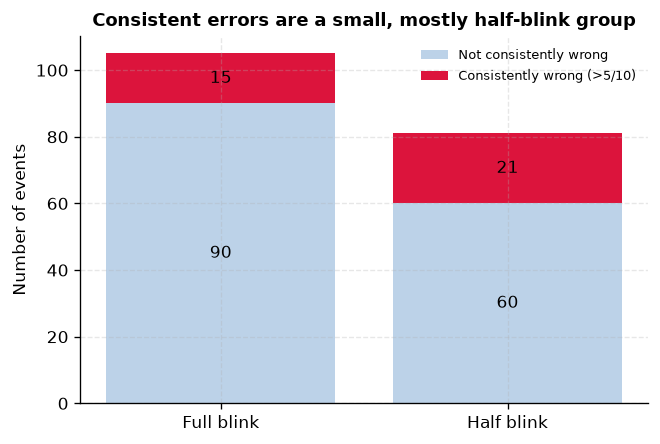

In [26]:
errors.plot_error_composition(blink_with_errors);

### 错误是否集中在某几段视频 / 某几匹马？

关键是不能只看绝对数量：事件多的视频天然会有更多错误。所以要用
**观测值 − 期望值**（期望 = 该组事件数 × 全体问题事件占比）。

In [27]:
video_summary = errors.check_overrepresentation(blink_events, mispredicted, "video_id")
video_summary

,total_blinks,problem_blinks,expected_problem_blinks,observed_minus_expected,problem_rate
video_id,,,,,
P-003,7,4,1.35,2.65,0.57
P-007,17,5,3.29,1.71,0.29
M-006,12,4,2.32,1.68,0.33
M-003,4,2,0.77,1.23,0.50
P-006,10,3,1.94,1.06,0.30
M-002,10,3,1.94,1.06,0.30
M-007,8,2,1.55,0.45,0.25
Y-001,3,1,0.58,0.42,0.33
M-008,19,4,3.68,0.32,0.21


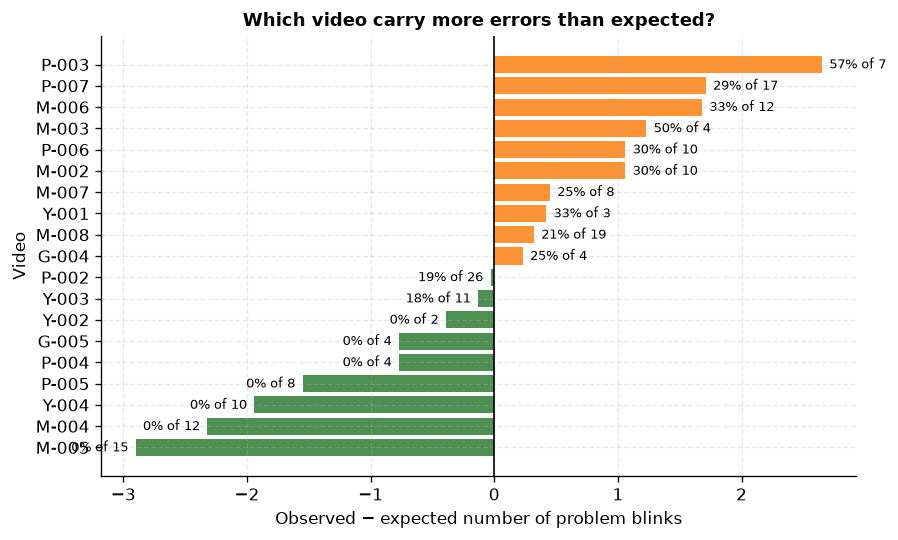

In [28]:
errors.plot_overrepresentation(video_summary, "Video", "fig13_overrep_video");

In [29]:
horse_summary = errors.check_overrepresentation(blink_events, mispredicted, "Horse_ID")
horse_summary

,total_blinks,problem_blinks,expected_problem_blinks,observed_minus_expected,problem_rate
Horse_ID,,,,,
P,72,17,13.94,3.06,0.24
M,80,15,15.48,-0.48,0.19
G,8,1,1.55,-0.55,0.12
Y,26,3,5.03,-2.03,0.12


结论与课程一致：没有哪一匹马明显"贡献"了大部分错误；个别视频的问题率偏高，
但这些视频的事件总数很少（例如 P-003 只有 7 个事件，错了 4 个就是 57%），
因此只能作为"值得回看原视频"的线索，不能当作定论。

## 10. 特征空间里的错误

把每个眨眼事件画成三维空间里的一个点（三个时长特征），用红圈标出"反复判错"的事件。
如果红圈散布在点云内部而不是聚在边缘，说明这些样本**在特征上和别的样本没区别** ——
那么问题就不在模型，而在特征本身。

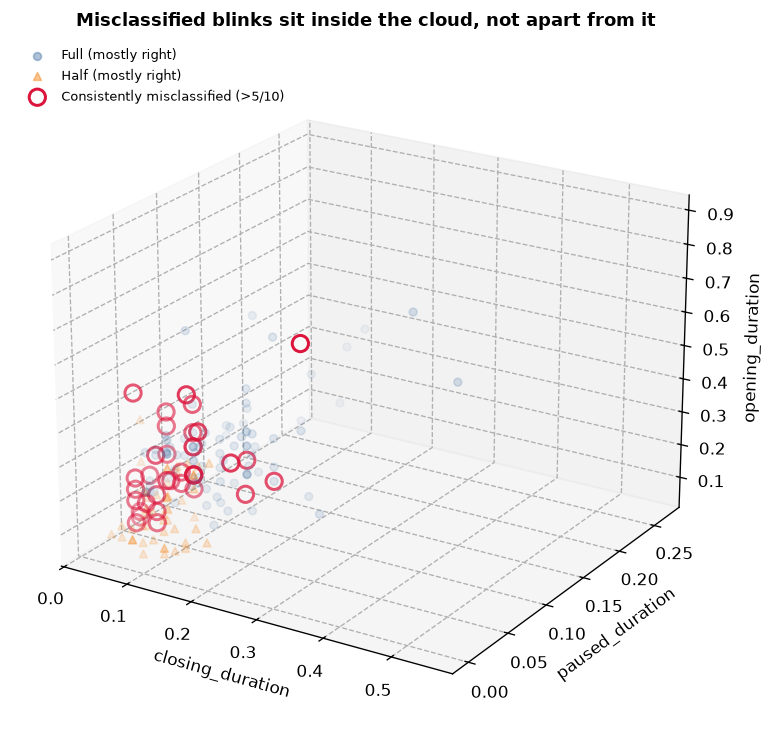

In [30]:
errors.plot_feature_space_3d(blink_with_errors);

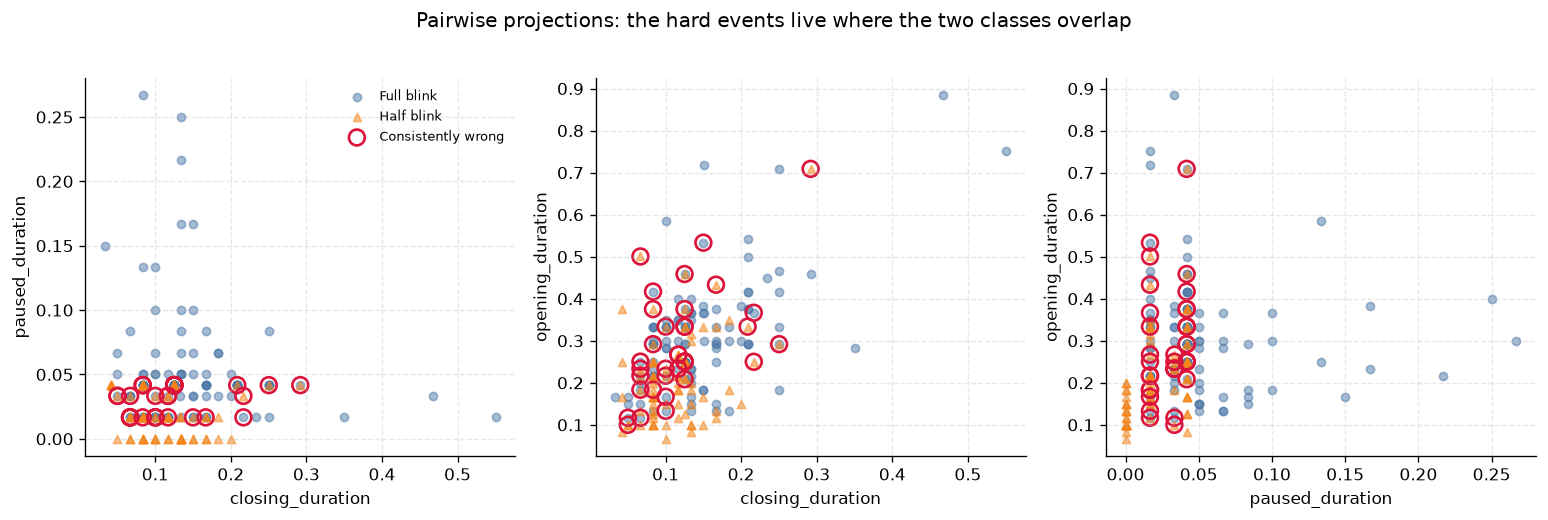

In [31]:
# 3D 图在静态报告里不好读，补一张两两投影图：判错的点落在两类点交界处，
# 说明问题在**特征重叠**，而不是模型选错了。
errors.plot_feature_space_pairgrid(blink_with_errors);

## 11. 复现对照表

| 课程给出的结果 | 课程值 | 本次复现值 | 是否一致 |
|---|---|---|---|
| 事件数 / 视频数 / 马匹数 | 186 / 19 / 4 | 186 / 19 / 4 | ✅ |
| 全眨眼 / 半眨眼数量 | 105 / 81 | 105 / 81 | ✅ |
| 懒惰基线准确率 | 0.56 | 0.56 | ✅ |
| 决策树（depth 10） | 0.76 | 0.76 | ✅ |
| 决策树叶节点数（depth 1/4/10） | 2 / 11 / 41 | 2 / 11 / 41 | ✅ |
| 随机森林（100 棵，depth 10） | 0.77 | 0.77 | ✅ |
| 随机森林最优组合（75/6/1） | 0.811828 | 0.811828 | ✅ |
| 随机森林（75/6/1） | 0.81 | 0.81 | ✅ |
| 召回率（决策树 F/H） | 76% / 80% | 76% / 80% | ✅ |
| 召回率（随机森林 F/H） | 86% / 74% | 86% / 74% | ✅ |
| 重复 10 次 CV（均值 ± 标准差） | 0.80 ± 0.01 | 0.80 ± 0.01 | ✅ |
| 反复判错事件数（>5/10） | 36 | 36 | ✅ |

所有数字都能对上，说明数据、划分方式、模型超参、评估口径都与课程一致。

差异只有一处：课程用 plotly 画交互式 3D 图，本复现用 matplotlib 画静态图
（便于嵌入报告），并额外补了 `total_duration` 的分布图、单特征 AUC 表、
错误阈值敏感性表 —— 这些是课程正文提到但未给代码的部分。

**下一步**：`04_extension_model_evaluation.ipynb` 会追问"0.80 这个数字到底有多可信"，
并系统检验特征/数据/模型三条改进路径。